<a href="https://www.kaggle.com/code/minhtuan11/it2058-da?scriptVersionId=364181120" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
!pip install -q --upgrade torch torchvision torchaudio torchinfo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 539.2/539.2 MB 3.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.2/519.2 MB 3.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 11.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 9.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 MB 14.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.9/404.9 MB 3.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 109.2 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 MB 46.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 80.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 218.3/218.3 MB 3.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 54.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import os
import random
import numpy as np
import torch
import torch._utils

# Ép gán thuộc tính _utils vào torch
setattr(torch, '_utils', torch._utils)

import torch.nn as nn
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights

# def seed_everything(seed=42):
#     random.seed(seed)
#     os.environ['PYTHONHASHSEED'] = str(seed)
#     np.random.seed(seed)
#     torch.manual_seed(seed)
#     torch.cuda.manual_seed(seed)
#     torch.cuda.manual_seed_all(seed)
#     torch.backends.cudnn.deterministic = True
#     torch.backends.cudnn.benchmark = False  

# SEED = 42
# seed_everything(SEED)

# Data Preprocessing

#### SỬ dụng tỉ lệ của tập datashet 50 25 25

In [3]:
import os
import pandas as pd

# Đường dẫn gốc chứa 3 thư mục: train, valid, test
base_dir = '/kaggle/input/datasets/minhtuan11/fetal-echocardiography-first-trimester/Fetal Echocardiography First Trimester'

def load_data_from_folder(split_name):
    folder_path = os.path.join(base_dir, split_name)
    filepaths, labels = [], []
    
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                filepaths.append(os.path.join(root, file))
                labels.append(os.path.basename(root))
                
    return pd.DataFrame({'filepath': filepaths, 'label': labels})

# 1. Đọc trực tiếp từ các thư mục có sẵn
train_df = load_data_from_folder('train')
val_df   = load_data_from_folder('valid')
test_df  = load_data_from_folder('test')

# 2. Gom tất cả nhãn, sắp xếp cố định theo thứ tự bảng chữ cái (tránh lệch idx)
unique_labels = sorted(list(set(train_df['label'].unique()) | 
                            set(val_df['label'].unique()) | 
                            set(test_df['label'].unique())))

label_to_idx = {label: idx for idx, label in enumerate(unique_labels)}

# 👉 3. TẠO TARGET_NAMES VÀ NUM_CLASSES CHO BÁO CÁO & MÔ HÌNH
num_classes = len(label_to_idx)
target_names = [label for label, _ in sorted(label_to_idx.items(), key=lambda x: x[1])]

# 4. Ánh xạ nhãn sang dạng số trên cả 3 tập
train_df['label_idx'] = train_df['label'].map(label_to_idx)
val_df['label_idx']   = val_df['label'].map(label_to_idx)
test_df['label_idx']  = test_df['label'].map(label_to_idx)

# 5. In kiểm tra thông tin xuất ra
print("=== THÔNG TIN DỮ LIỆU ĐÃ CHUẨN HÓA NHÃN ===")
print(f"Danh sách các lớp ({num_classes} lớp): {target_names}")
print(f"Tập Train: {len(train_df)} ảnh")
print(f"Tập Valid: {len(val_df)} ảnh")
print(f"Tập Test:  {len(test_df)} ảnh\n")

# Bảng tổng hợp chi tiết theo từng lớp
split_summary = pd.DataFrame({
    'Train': train_df['label'].value_counts(),
    'Valid': val_df['label'].value_counts(),
    'Test':  test_df['label'].value_counts()
}).fillna(0).astype(int)

print("--- Phân bố mẫu trong các thư mục gốc ---")
print(split_summary)

=== THÔNG TIN DỮ LIỆU ĐÃ CHUẨN HÓA NHÃN ===
Danh sách các lớp (5 lớp): ['Aorta', 'Flows', 'Other', 'V sign', 'X sign']
Tập Train: 3989 ảnh
Tập Valid: 1352 ảnh
Tập Test:  1379 ảnh

--- Phân bố mẫu trong các thư mục gốc ---
        Train  Valid  Test
label                     
Other    1490    628   689
V sign   1049    362   259
Flows     700    175   219
Aorta     490     96   133
X sign    260     91    79


#### Chia theo paper 60 20 20 

In [4]:
# import os
# import re
# import pandas as pd
# import numpy as np
# from sklearn.model_selection import GroupShuffleSplit

# base_dir = '/kaggle/input/datasets/minhtuan11/fetal-echocardiography-first-trimester/Fetal Echocardiography First Trimester'

# filepaths, labels, patient_ids = [], [], []

# for root, dirs, files in os.walk(base_dir):
#     for file in files:
#         if file.lower().endswith(('.png', '.jpg', '.jpeg')):
#             full_path = os.path.join(root, file)
            
#             # 1. Lấy tên lớp từ thư mục chứa file
#             label = os.path.basename(root)
            
#             # 2. Tách Mã Bệnh Nhân từ tên file (Ví dụ: "Flows test (137).png" -> "137")
#             match = re.search(r"\((\d+)\)", file)
#             patient_id = match.group(1) if match else os.path.splitext(file)[0]

#             filepaths.append(full_path)
#             labels.append(label)
#             patient_ids.append(patient_id)

# # Tạo DataFrame tổng
# df = pd.DataFrame({
#     'filepath': filepaths, 
#     'label': labels, 
#     'patient_id': patient_ids
# })

# # 3. TẠO CỘT 'label_idx' TRỰC TIẾP TRÊN DF GỐC (Tránh lỗi KeyError)
# unique_labels = sorted(df['label'].unique())
# label_to_idx = {label: idx for idx, label in enumerate(unique_labels)}
# df['label_idx'] = df['label'].map(label_to_idx)

# # 4. TẠO BỘ BIẾN XUẤT RA CHO BLOCK TRAIN
# num_classes = len(label_to_idx)
# target_names = [label for label, _ in sorted(label_to_idx.items(), key=lambda x: x[1])]

# # 5. CHIA TẬP THEO PATIENT-LEVEL (Train 60%, Valid 20%, Test 20%)
# gss_train = GroupShuffleSplit(n_splits=1, test_size=0.40, random_state=42)
# train_idx, temp_idx = next(gss_train.split(df, groups=df['patient_id']))

# train_df = df.iloc[train_idx].copy().reset_index(drop=True)
# temp_df  = df.iloc[temp_idx].copy().reset_index(drop=True)

# gss_val = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
# val_idx, test_idx = next(gss_val.split(temp_df, groups=temp_df['patient_id']))

# val_df  = temp_df.iloc[val_idx].copy().reset_index(drop=True)
# test_df = temp_df.iloc[test_idx].copy().reset_index(drop=True)

# print("=== HOÀN TẤT XỬ LÝ DỮ LIỆU (BLOCK 1) ===")
# print(f"Tổng số ảnh: {len(df)}")
# print(f"Danh sách các lớp ({num_classes} lớp): {target_names}")
# print(f"Số lượng bệnh nhân thực tế: {df['patient_id'].nunique()}")
# print(f"Phân bổ: Train={len(train_df)} | Valid={len(val_df)} | Test={len(test_df)} ảnh")
# print(f"Các cột đã sẵn sàng: {list(train_df.columns)}")

In [5]:
!find '/kaggle/input/datasets/minhtuan11/fetal-echocardiography-first-trimester/Fetal Echocardiography First Trimester/test' -type f | wc -l

1380


# Model config

### Exit early

In [6]:
import torch
import torch.nn as nn

class ExitHead(nn.Module):
    def __init__(self, in_channels, hidden_channels, num_classes, dropout_p=0.3):
        super().__init__()
        # 1. Conv 1x1: Giảm số lượng channel
        self.reduce_conv = nn.Conv2d(in_channels, hidden_channels, kernel_size=1)
        
        # 2. GAP (Global Average Pooling)
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        
        # 3. LayerNorm
        self.norm = nn.LayerNorm(hidden_channels)
        
        # 4. Dropout: Chống overfitting
        self.dropout = nn.Dropout(p=dropout_p)
        
        # 5. Linear Classifier
        self.classifier = nn.Linear(hidden_channels, num_classes)

    def forward(self, x):
        x = self.reduce_conv(x)
        x = self.gap(x)
        x = torch.flatten(x, start_dim=1)
        x = self.norm(x)
        x = self.dropout(x)
        out = self.classifier(x)
        return out

### Multi Exit Convnext

In [7]:
# =============================================================================
# MÔ HÌNH MULTI-EXIT CONVNEXT GỐC (Tích hợp Dropout cả 3 Exit)
# =============================================================================
class MultiExitConvNeXt(nn.Module):
    def __init__(self, num_classes=5, dropout_p=0.3):
        super().__init__()
        
        # 1. Tải mô hình ConvNeXt-Tiny pre-trained
        backbone = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
        features = backbone.features

        # 2. Rã mô hình thành 3 khúc (Slicing)
        self.part1 = features[:4]   # Hết Stage 2 (in_channels=192)
        self.part2 = features[4:6]  # Hết Stage 3 (in_channels=384)
        self.part3 = features[6:8]  # Hết Stage 4 (in_channels=768)

        # 3. Lắp ráp các Exit Heads với Dropout
        self.exit1 = ExitHead(in_channels=192, hidden_channels=64, num_classes=num_classes, dropout_p=dropout_p)
        self.exit2 = ExitHead(in_channels=384, hidden_channels=128, num_classes=num_classes, dropout_p=dropout_p)

        # Exit 3 (Main Head): Tái cấu trúc Classifier gốc và chèn Dropout
        self.avgpool = backbone.avgpool
        self.exit3 = nn.Sequential(
            backbone.classifier[0],     # LayerNorm2d
            backbone.classifier[1],     # Flatten
            nn.Dropout(p=dropout_p),     # Dropout ngay trước Linear cuối
            nn.Linear(768, num_classes)
        )

    def forward(self, x):
        # Stage 1 + Stage 2
        x = self.part1(x)
        y1 = self.exit1(x)

        # Stage 3
        x = self.part2(x)
        y2 = self.exit2(x)

        # Stage 4 (Main Head)
        x = self.part3(x)
        x = self.avgpool(x)
        y3 = self.exit3(x)

        return y1, y2, y3

### MultiExit_SelfKDLoss

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MultiExit_SelfKDLoss(nn.Module):
    def __init__(self, base_criterion, T=3.0, lambda_kd=0.5, weights=(0.2, 0.3, 1.0)):
        """
        base_criterion: Hàm loss cơ bản để tính với nhãn thật (VD: Focal Loss hoặc CrossEntropy có class weights)
        T: Temperature để làm mềm xác suất (thường từ 2.0 đến 4.0)
        lambda_kd: Trọng số của hàm suy luận KL Divergence (tỉ lệ học từ Thầy)
        weights: Trọng số w1, w2, w3 để cộng tổng loss 3 nhánh
        """
        super().__init__()
        self.base_criterion = base_criterion
        self.T = T
        self.lambda_kd = lambda_kd
        self.w1, self.w2, self.w3 = weights
        self.kl_div = nn.KLDivLoss(reduction='batchmean')

    def forward(self, outputs, targets):
        y1, y2, y3 = outputs

        # 1. TÍNH LOSS CHO NGƯỜI THẦY (EXIT 3) - Chỉ học từ nhãn thật (Hard Labels)
        loss3 = self.base_criterion(y3, targets)

        # 2. CHUẨN BỊ TRI THỨC TỪ THẦY (Soft Labels)
        # Phải có .detach() để chặn Gradient không chảy ngược về làm hỏng Exit 3
        soft_teacher = F.softmax(y3 / self.T, dim=1).detach()

        # 3. TÍNH LOSS CHO HỌC TRÒ 1 (EXIT 1)
        # a. Học từ nhãn thật
        loss1_hard = self.base_criterion(y1, targets)
        # b. Học từ Thầy (phải dùng log_softmax cho đầu vào của KLD)
        log_soft_y1 = F.log_softmax(y1 / self.T, dim=1)
        loss1_kd = self.kl_div(log_soft_y1, soft_teacher) * (self.T ** 2) # Nhân T^2 để cân bằng gradient
        # c. Tổng loss của Exit 1
        loss1 = loss1_hard + self.lambda_kd * loss1_kd

        # 4. TÍNH LOSS CHO HỌC TRÒ 2 (EXIT 2)
        loss2_hard = self.base_criterion(y2, targets)
        log_soft_y2 = F.log_softmax(y2 / self.T, dim=1)
        loss2_kd = self.kl_div(log_soft_y2, soft_teacher) * (self.T ** 2)
        loss2 = loss2_hard + self.lambda_kd * loss2_kd

        # 5. TỔNG HỢP LOSS CUỐI CÙNG QUA LOSS WEIGHTING
        total_loss = (self.w1 * loss1) + (self.w2 * loss2) + (self.w3 * loss3)

        return total_loss, loss1.item(), loss2.item(), loss3.item()

In [9]:
### Multi Exit Convnext DRAS

In [10]:
# import torch
# import torch._utils

# # Ép gán thuộc tính _utils vào torch để tránh lỗi AttributeError
# setattr(torch, '_utils', torch._utils)

# import torch.nn as nn
# from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights

# # =============================================================================
# # 1. MODULE DUAL-REGION ARTIFACT SUPPRESSION (DRAS) - ĐÃ SỬA GROUPNORM
# # =============================================================================
# class DRASModule(nn.Module):
#     def __init__(self, in_channels, reduction=16, use_prior=True):
#         super().__init__()
#         self.use_prior = use_prior
#         hidden_dim = in_channels // reduction  # 192//16 = 12 kênh, 384//16 = 24 kênh
        
#         # Spatial Attention Gate
#         self.spatial_gate = nn.Sequential(
#             nn.Conv2d(in_channels, hidden_dim, kernel_size=1),
#             nn.GroupNorm(4, hidden_dim),  # 🎯 Đã sửa từ 8 -> 4 (12 và 24 đều chia hết cho 4)
#             nn.GELU(),
#             nn.Conv2d(hidden_dim, 1, kernel_size=3, padding=1),
#             nn.Sigmoid()
#         )

#     def forward(self, x):
#         B, C, H, W = x.shape
#         attn = self.spatial_gate(x)  # Shape: [B, 1, H, W]
        
#         if self.use_prior:
#             prior_mask = torch.ones((1, 1, H, W), device=x.device, dtype=x.dtype)
            
#             # Region 1: Che góc trên-phải (Chữ thông số máy SRI II, PRF...)
#             prior_mask[:, :, :int(H * 0.35), int(W * 0.85):] = 0.05
            
#             # Region 2: Che góc dưới-trái (Ô Thumbnail)
#             prior_mask[:, :, int(H * 0.70):, :int(W * 0.35)] = 0.05
            
#             attn = attn * prior_mask
            
#         return x * attn


# # =============================================================================
# # 2. LỚP EXIT HEAD PHỤ (Dùng cho Exit 1 & Exit 2)
# # =============================================================================
# class ExitHead(nn.Module):
#     def __init__(self, in_channels, hidden_channels, num_classes):
#         super().__init__()
#         self.head = nn.Sequential(
#             nn.AdaptiveAvgPool2d(1),
#             nn.Flatten(),
#             nn.Linear(in_channels, hidden_channels),
#             nn.LayerNorm(hidden_channels),
#             nn.GELU(),
#             nn.Dropout(0.2),
#             nn.Linear(hidden_channels, num_classes)
#         )

#     def forward(self, x):
#         return self.head(x)


# # =============================================================================
# # 3. MÔ HÌNH MULTI-EXIT CONVNEXT TÍCH HỢP DRAS
# # =============================================================================
# class MultiExitConvNeXtDRAS(nn.Module):
#     def __init__(self, num_classes=5, use_dras_prior=True):
#         super().__init__()
        
#         # 1. Tải backbone ConvNeXt-Tiny pre-trained
#         backbone = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
#         features = backbone.features

#         # 2. Slicing Backbone thành 3 phần
#         self.part1 = features[:4]   # Output Channels: 192 (Hết Stage 2)
#         self.part2 = features[4:6]  # Output Channels: 384 (Hết Stage 3)
#         self.part3 = features[6:8]  # Output Channels: 768 (Hết Stage 4)

#         # 3. Chèn Module DRAS vào sau Stage 2 & Stage 3
#         self.dras1 = DRASModule(in_channels=192, use_prior=use_dras_prior)
#         self.dras2 = DRASModule(in_channels=384, use_prior=use_dras_prior)

#         # 4. Lắp ráp 3 Exit Heads
#         self.exit1 = ExitHead(in_channels=192, hidden_channels=64, num_classes=num_classes)
#         self.exit2 = ExitHead(in_channels=384, hidden_channels=128, num_classes=num_classes)

#         # Exit 3 (Main Head)
#         self.avgpool = backbone.avgpool
#         self.exit3 = backbone.classifier
#         self.exit3[-1] = nn.Linear(768, num_classes)

#     def forward(self, x):
#         # Stage 1 + Stage 2
#         x = self.part1(x)
#         x = self.dras1(x)        # DRAS dập nhiễu Stage 2
#         y1 = self.exit1(x)

#         # Stage 3
#         x = self.part2(x)
#         x = self.dras2(x)        # DRAS dập nhiễu Stage 3
#         y2 = self.exit2(x)

#         # Stage 4 (Main Head)
#         x = self.part3(x)
#         x = self.avgpool(x)
#         y3 = self.exit3(x)

#         return y1, y2, y3

### Test 

In [11]:
# Test khởi tạo mô hình
if __name__ == "__main__":
    model = MultiExitConvNeXt(num_classes=5, dropout_p=0.3)
    dummy_input = torch.randn(2, 3, 224, 224)
    y1, y2, y3 = model(dummy_input)
    
    print("✅ Khởi tạo thành công MultiExitConvNeXt + Dropout!")
    print(f"Shape Exit 1: {y1.shape}")
    print(f"Shape Exit 2: {y2.shape}")
    print(f"Shape Exit 3: {y3.shape}")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 178MB/s]  


✅ Khởi tạo thành công MultiExitConvNeXt + Dropout!
Shape Exit 1: torch.Size([2, 5])
Shape Exit 2: torch.Size([2, 5])
Shape Exit 3: torch.Size([2, 5])


# Main

### Xử lí ảnh 

In [12]:
import cv2
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, f1_score
from torchinfo import summary

In [13]:
import cv2
import numpy as np

### Cắt theo ROI
def preprocess_ultrasound_image(image_path, 
                                top_left_h_ratio=0.40, 
                                top_left_w_ratio=0.08,
                                pad_x=50,             # 🎯 Nới rộng 50px sang 2 bên từ mép màu sạch
                                pad_y=50,             # 🎯 Nới rộng 50px lên/xuống từ mép màu sạch
                                max_noise_dist=120):  # 🎯 Ngưỡng khoảng cách tối đa để loại đốm nhiễu (px)
    """
    Tiền xử lý ảnh siêu âm thai nhi:
    - Bắt khối màu Doppler (Đỏ + Xanh dương).
    - Lọc bỏ 100% đốm màu nằm cách xa cụm tim chính quá max_noise_dist.
    - Lấy 100% mép màu thực tế của dải tim thai sạch nhiễu -> Nới rộng padding ra xung quanh.
    """
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"Không thể đọc file: {image_path}")
        
    H, W, C = img.shape
    mid_x = W // 2

    # =========================================================================
    # 1. NỬA TRÁI: CHE CỘT THANG MÀU GÓC TRÊN TRÁI
    # =========================================================================
    left_img = img[:, :mid_x].copy()
    mask_h = int(H * top_left_h_ratio)
    mask_w = int(mid_x * top_left_w_ratio)
    left_img[0:mask_h, 0:mask_w] = 0

    # =========================================================================
    # 2. NỬA PHẢI: BẮT MÀU DOPPLER (ĐỎ + XANH DƯƠNG)
    # =========================================================================
    right_raw = img[:, mid_x:].copy()
    hsv_right = cv2.cvtColor(right_raw, cv2.COLOR_BGR2HSV)

    # Dải màu Doppler Đỏ & Xanh dương
    lower_red1, upper_red1 = np.array([0, 40, 40]), np.array([15, 255, 255])
    lower_red2, upper_red2 = np.array([155, 40, 40]), np.array([180, 255, 255])
    lower_blue, upper_blue = np.array([85, 40, 40]), np.array([140, 255, 255])

    mask_r1 = cv2.inRange(hsv_right, lower_red1, upper_red1)
    mask_r2 = cv2.inRange(hsv_right, lower_red2, upper_red2)
    mask_b  = cv2.inRange(hsv_right, lower_blue, upper_blue)
    doppler_mask = mask_r1 | mask_r2 | mask_b

    # Lọc bỏ rác UI ngoài lề trên Mask
    doppler_mask[:int(H * 0.10), :] = 0
    doppler_mask[:, int(mid_x * 0.82):] = 0
    doppler_mask[int(H * 0.70):, :int(mid_x * 0.38)] = 0

    contours, _ = cv2.findContours(doppler_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    valid_contours = [c for c in contours if cv2.contourArea(c) > 15]

    right_processed = np.zeros_like(right_raw)

    # =========================================================================
    # 3. LỌC ĐỐM NHIỄU XA & MỞ RỘNG TỪ MÉP MÀU CHUẨN
    # =========================================================================
    if valid_contours:
        # A. Tìm khối màu lớn nhất (Cụm tim chính)
        main_contour = max(valid_contours, key=cv2.contourArea)
        M = cv2.moments(main_contour)
        if M["m00"] > 0:
            cx_main = int(M["m10"] / M["m00"])
            cy_main = int(M["m01"] / M["m00"])
        else:
            pts_m = main_contour[:, 0, :]
            cx_main, cy_main = int(np.mean(pts_m[:, 0])), int(np.mean(pts_m[:, 1]))

        # B. 🎯 LỌC BỎ ĐỐM NHIỄU: Chỉ giữ lại các đốm màu nằm gần cụm chính (< max_noise_dist)
        clean_color_contours = []
        for c in valid_contours:
            pts_c = c[:, 0, :]
            mc_x, mc_y = np.mean(pts_c[:, 0]), np.mean(pts_c[:, 1])
            dist = np.sqrt((mc_x - cx_main)**2 + (mc_y - cy_main)**2)
            
            # Nếu đốm màu nằm trong bán kính cho phép -> GIỮ LẠI (Thuộc tim thai)
            if dist <= max_noise_dist:
                clean_color_contours.append(c)

        if not clean_color_contours:
            clean_color_contours = [main_contour]

        # C. LẤY 100% TẮT CẢ PIXEL MÀU SẠCH (CẢ ĐỎ & XANH DƯƠNG)
        all_clean_pts = np.vstack([c[:, 0, :] for c in clean_color_contours])
        color_x_min = np.min(all_clean_pts[:, 0])
        color_x_max = np.max(all_clean_pts[:, 0])
        color_y_min = np.min(all_clean_pts[:, 1])
        color_y_max = np.max(all_clean_pts[:, 1])

        # D. 🎯 MỞ RỘNG PADDING RA NGOÀI TỪ MÁP MÀU SẠCH (PAD_X, PAD_Y)
        x_min = max(0, color_x_min - pad_x)
        x_max = min(mid_x, color_x_max + pad_x)
        y_min = max(0, color_y_min - pad_y)
        y_max = min(H, color_y_max + pad_y)

        # Cắt nguyên bản 100% pixel vùng tim thai
        right_processed[y_min:y_max, x_min:x_max] = right_raw[y_min:y_max, x_min:x_max]

    else:
        # Dự phòng cắt chính giữa màn hình nếu ảnh B-mode không có màu
        center_x, center_y = mid_x // 2, H // 2
        x_min, x_max = max(0, center_x - 120), min(mid_x, center_x + 120)
        y_min, y_max = max(0, center_y - 120), min(H, center_y + 120)
        right_processed[y_min:y_max, x_min:x_max] = right_raw[y_min:y_max, x_min:x_max]

    # Đè đen bảo vệ dải chữ UI ngoài lề
    right_processed[:int(H * 0.35), int(mid_x * 0.88):] = 0  # Cột chữ góc trên-phải
    right_processed[int(H * 0.70):, :int(mid_x * 0.38)] = 0  # Ô Thumbnail góc dưới-trái

    final_img_bgr = np.hstack((left_img, right_processed))
    return final_img_bgr

### Test image 

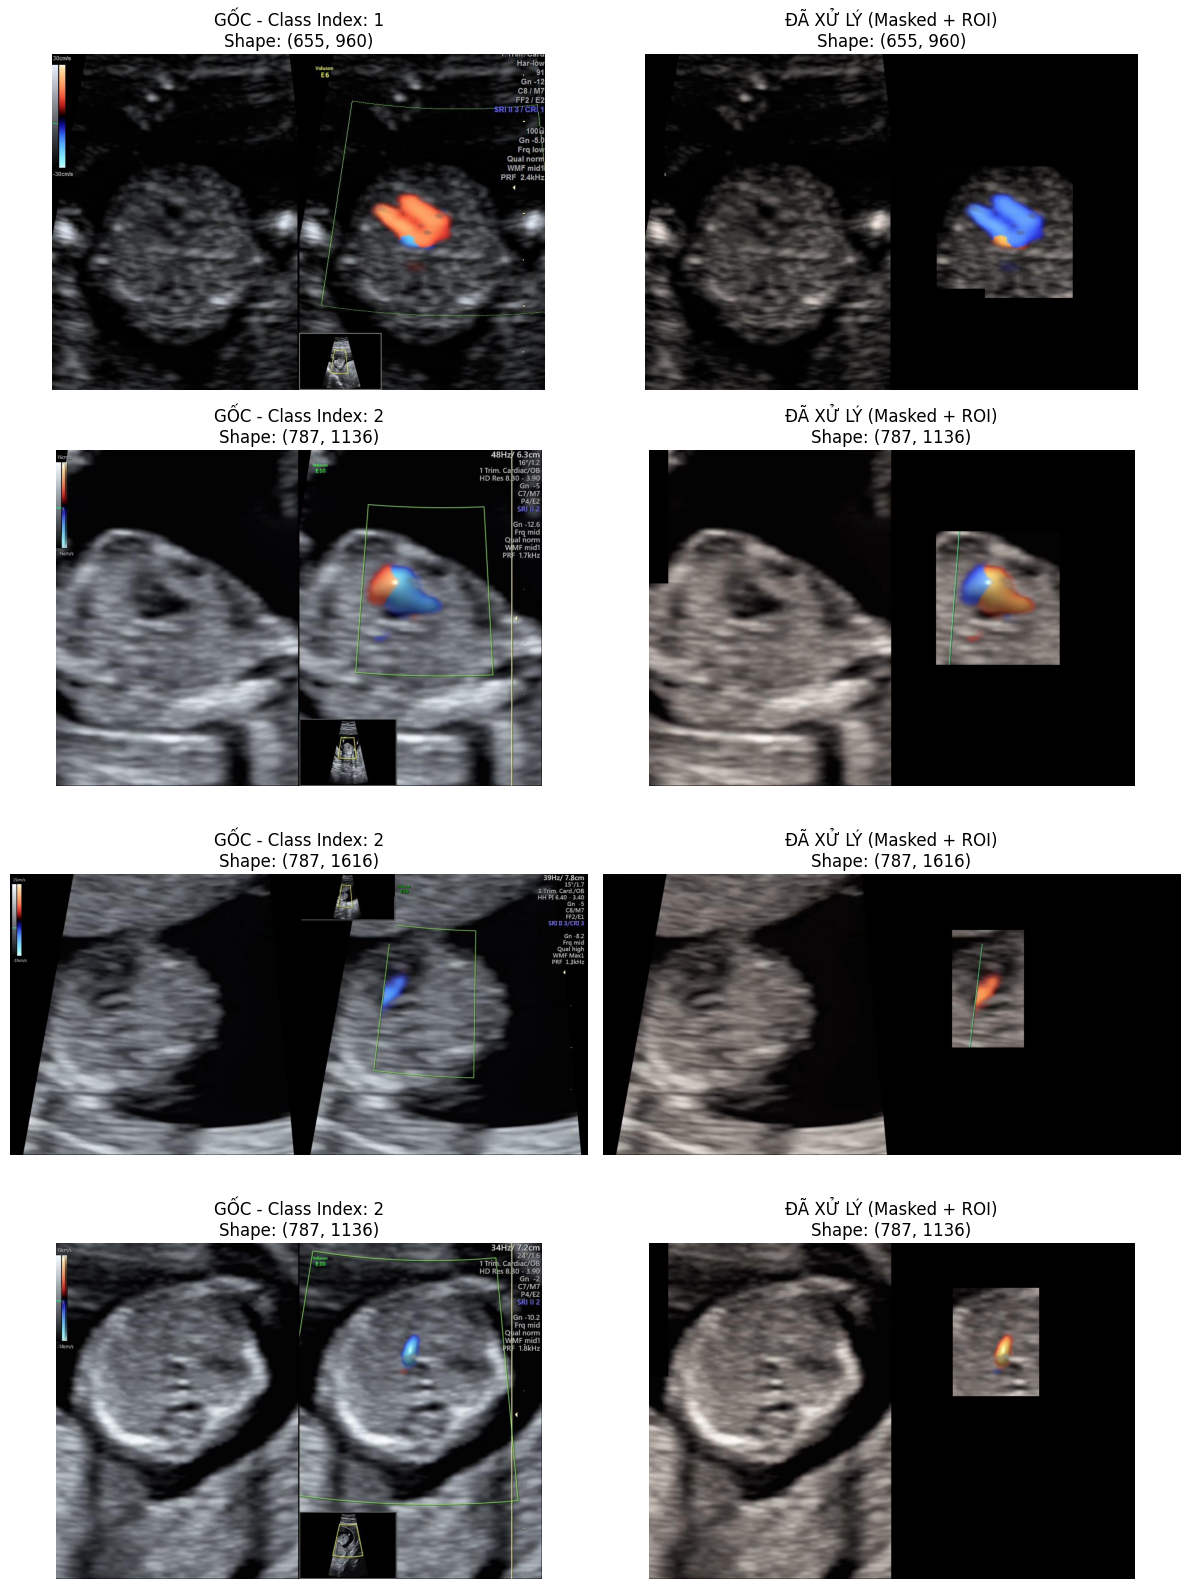

In [15]:
import matplotlib.pyplot as plt
import random

def visualize_preprocessed_samples(df, num_samples=4):
    """
    Hiển thị so sánh ảnh gốc và ảnh sau khi đã Masking & Crop ROI.
    """
    sample_indices = random.sample(range(len(df)), min(num_samples, len(df)))
    
    plt.figure(figsize=(12, 4 * num_samples))
    
    for idx, sample_idx in enumerate(sample_indices):
        img_path = df.loc[sample_idx, 'filepath']
        label = df.loc[sample_idx, 'label_idx']
        
        # 1. Đọc ảnh gốc
        raw_img = cv2.imread(img_path)
        raw_img = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
        
        # 2. Xử lý qua hàm mới|
        processed_img = preprocess_ultrasound_image(img_path)
        
        # Plot Ảnh Gốc
        plt.subplot(num_samples, 2, idx * 2 + 1)
        plt.imshow(raw_img)
        plt.title(f"GỐC - Class Index: {label}\nShape: {raw_img.shape[:2]}")
        plt.axis('off')
        
        # Plot Ảnh Đã Xử Lý
        plt.subplot(num_samples, 2, idx * 2 + 2)
        plt.imshow(processed_img)
        plt.title(f"ĐÃ XỬ LÝ (Masked + ROI)\nShape: {processed_img.shape[:2]}")
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()

# ==========================================
# GỌI HÀM ĐỂ XEM KẾT QUẢ (Truyền DataFrame của bạn vào đây)
# ==========================================
visualize_preprocessed_samples(train_df, num_samples=4) 
# hoặc:
#visualize_preprocessed_samples(df_test, num_samples=4)

In [16]:
import cv2
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

def visualize_interactive_samples(df, target_names=None):
    """
    Bộ duyệt ảnh tương tác: Xem từng ảnh một bằng nút bấm Next/Prev hoặc Slider.
    """
    total_samples = len(df)
    
    # 1. Khởi tạo các Widget Giao diện
    btn_prev = widgets.Button(description="◀ Trước", button_style='info', icon='arrow-left')
    btn_next = widgets.Button(description="Tiếp ▶", button_style='info', icon='arrow-right')
    slider = widgets.IntSlider(
        value=0, 
        min=0, 
        max=total_samples - 1, 
        step=1, 
        description='Index:', 
        continuous_update=False,
        layout=widgets.Layout(width='50%')
    )
    output = widgets.Output()

    # 2. Hàm vẽ ảnh khi index thay đổi
    def render_image(idx):
        with output:
            clear_output(wait=True)
            
            img_path = df.loc[idx, 'filepath']
            label_idx = df.loc[idx, 'label_idx']
            
            # Lấy tên nhãn dạng chữ
            if 'label' in df.columns:
                label_name = df.loc[idx, 'label']
            elif target_names and label_idx < len(target_names):
                label_name = target_names[label_idx]
            else:
                label_name = f"Class_{label_idx}"
            
            # Đọc & chuyển RGB ảnh gốc
            raw_img = cv2.imread(img_path)
            raw_rgb = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
            
            # Tiền xử lý & chuyển RGB cho ảnh hiển thị
            processed_bgr = preprocess_ultrasound_image(img_path)
            processed_rgb = cv2.cvtColor(processed_bgr, cv2.COLOR_BGR2RGB)
            
            # Vẽ hình
            fig, axes = plt.subplots(1, 2, figsize=(13, 6))
            
            # Column 1: Ảnh gốc
            axes[0].imshow(raw_rgb)
            axes[0].set_title(
                f"GỐC - Index [{idx}/{total_samples - 1}]\n"
                f"Lớp: {label_name} (ID: {label_idx}) | Shape: {raw_img.shape[:2]}", 
                fontsize=12, fontweight='bold', color='navy'
            )
            axes[0].axis('off')
            
            # Column 2: Ảnh xử lý
            axes[1].imshow(processed_rgb)
            axes[1].set_title(
                f"ĐÃ XỬ LÝ (Masked + ROI)\n"
                f"Shape: {processed_bgr.shape[:2]}", 
                fontsize=12, fontweight='bold', color='darkgreen'
            )
            axes[1].axis('off')
            
            plt.tight_layout()
            plt.show()

    # 3. Định nghĩa sự kiện bấm nút
    def on_prev_clicked(b):
        if slider.value > 0:
            slider.value -= 1

    def on_next_clicked(b):
        if slider.value < total_samples - 1:
            slider.value += 1

    def on_slider_change(change):
        render_image(change['new'])

    # Gán Event Handlers
    btn_prev.on_click(on_prev_clicked)
    btn_next.on_click(on_next_clicked)
    slider.observe(on_slider_change, names='value')

    # 4. Hiển thị Control Panel & Output
    controls = widgets.HBox([btn_prev, slider, btn_next], layout=widgets.Layout(align_items='center', justify_content='center'))
    display(controls, output)
    
    # Load ảnh đầu tiên
    render_image(0)

# GỌI HÀM DUYỆT ẢNH
visualize_interactive_samples(train_df, target_names=target_names)

Output()

### PyTorch Dataset & DataLoaders

In [17]:
class UltrasoundDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'filepath']
        label = self.df.loc[idx, 'label_idx']

        # Preprocessing & Color conversion
        img_bgr = preprocess_ultrasound_image(img_path)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_pil = Image.fromarray(img_rgb)

        # Transform Pipeline
        if self.transform:
            img_tensor = self.transform(img_pil)
        else:
            img_tensor = transforms.ToTensor()(img_pil)

        return img_tensor, torch.tensor(label, dtype=torch.long)


# Pipeline biến đổi kích thước & chuẩn hóa
transform_pipeline = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


# ==========================================
# 2. SEED WORKER & HÀM TẠO DATALOADERS
# ==========================================
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def get_dataloaders(train_df, val_df, test_df, seed, batch_size=32, num_workers=2):
    """
    Hàm tạo DataLoader theo từng seed truyền vào để đảm bảo tính ngẫu nhiên
    nhưng vẫn tái lập (reproducible) được.
    """
    g = torch.Generator()
    g.manual_seed(seed)

    train_loader = DataLoader(
        UltrasoundDataset(train_df, transform_pipeline), 
        batch_size=batch_size, 
        shuffle=True, 
        num_workers=num_workers,
        worker_init_fn=seed_worker,  
        generator=g
    )

    val_loader = DataLoader(
        UltrasoundDataset(val_df, transform_pipeline), 
        batch_size=batch_size, 
        shuffle=False, 
        num_workers=num_workers
    )

    test_loader = DataLoader(
        UltrasoundDataset(test_df, transform_pipeline), 
        batch_size=batch_size, 
        shuffle=False, 
        num_workers=num_workers
    )

    return train_loader, val_loader, test_loader

### Focal Loss & Class Weights  

In [18]:
# ==========================================
# FOCAL LOSS & CLASS WEIGHTS
# ==========================================
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=self.alpha)
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['label_idx']),
    y=train_df['label_idx'].values
)
alpha = torch.tensor(class_weights, dtype=torch.float)

### Khởi tạo mô hình & Tính toán khối lượng

In [19]:
import torch
from torchinfo import summary  

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang chạy trên thiết bị: {device}\n")

# Khởi tạo mô hình MultiExitConvNeXt
num_classes = 5
model = MultiExitConvNeXt(num_classes=num_classes)
model = model.to(device)

print("\n--- BẢNG CẤU TRÚC VÀ KHỐI LƯỢNG TÍNH TOÁN CỦA MÔ HÌNH ---")

# 👉 BẮT BUỘC BỌC print() VÀ TRUYỀN ĐÚNG INPUT SHAPE
print(
    summary(
        model, 
        input_size=(32, 3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "params_percent", "kernel_size", "mult_adds"],
        row_settings=["var_names"]
    )
)

print("-" * 60 + "\n")

Đang chạy trên thiết bị: cuda


--- BẢNG CẤU TRÚC VÀ KHỐI LƯỢNG TÍNH TOÁN CỦA MÔ HÌNH ---
Layer (type (var_name))                                 Input Shape               Output Shape              Param #                   Param %                   Kernel Shape              Mult-Adds
MultiExitConvNeXt (MultiExitConvNeXt)                   [32, 3, 224, 224]         [32, 5]                   --                             --                   --                        --
├─Sequential (part1)                                    [32, 3, 224, 224]         [32, 192, 28, 28]         --                             --                   --                        --
│    └─Conv2dNormActivation (0)                         [32, 3, 224, 224]         [32, 96, 56, 56]          --                             --                   --                        --
│    │    └─Conv2d (0)                                  [32, 3, 224, 224]         [32, 96, 56, 56]          4,704                       0.02%      

### Test DataLoader Đơn Luồng

In [20]:
import random
from torch.utils.data import DataLoader

SEED = 24

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(SEED)

# Khởi tạo DataLoader
train_loader = DataLoader(
    UltrasoundDataset(train_df, transform_pipeline), 
    batch_size=32, 
    shuffle=True, 
    num_workers=2,
    drop_last=True,
    worker_init_fn=seed_worker,  
    generator=g                
)
val_loader  = DataLoader(UltrasoundDataset(val_df, transform_pipeline), batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(UltrasoundDataset(test_df, transform_pipeline), batch_size=32, shuffle=False, num_workers=2)

# --- KIỂM TRA BATCH ĐẦU TIÊN ---
print("\n🧪 [BATCH TEST] Kiểm tra ghép Batch Tensor...")
try:
    # Dùng luôn train_loader tạo từ hàm get_dataloaders với seed cố định (ví dụ 42)
    demo_train_loader, _, _ = get_dataloaders(train_df, val_df, test_df, seed=42)
    
    test_imgs, test_lbls = next(iter(demo_train_loader))
    print(f"✅ Batch Images Shape : {test_imgs.shape}") # torch.Size([32, 3, 224, 224])
    print(f"✅ Batch Labels Shape : {test_lbls.shape}") # torch.Size([32])
    print(f"✅ Data Type           : {test_imgs.dtype}")
except Exception as e:
    print(f"❌ Lỗi ghép Batch: {e}")


🧪 [BATCH TEST] Kiểm tra ghép Batch Tensor...
✅ Batch Images Shape : torch.Size([32, 3, 224, 224])
✅ Batch Labels Shape : torch.Size([32])
✅ Data Type           : torch.float32


## Training

In [21]:
import os
import copy
import random
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# 1. Danh sách các Seed cần chạy
##SEEDS = [42, 100, 2024, 777, 999]
SEEDS = [42]
# 2. Cấu hình thư mục lưu mô hình và kết quả
SAVE_DIR = "./saved_runs"
os.makedirs(SAVE_DIR, exist_ok=True)

# 3. Cấu hình Tham số Huấn luyện
EPOCHS = 15
PATIENCE = 4
BATCH_SIZE = 32
LR = 1e-4
WEIGHT_DECAY = 0.05
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 4. Hàm cố định Seed tổng quát
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # Bật benchmark để CUDNN tự tìm thuật toán tối ưu nhất cho phần cứng
    # torch.backends.cudnn.deterministic = False 
    # torch.backends.cudnn.benchmark = True

print(f"✅ Cấu hình hoàn tất. Số lượng seeds sẽ chạy: {len(SEEDS)}")
print(f"📁 Thư mục lưu kết quả: {os.path.abspath(SAVE_DIR)}")

✅ Cấu hình hoàn tất. Số lượng seeds sẽ chạy: 1
📁 Thư mục lưu kết quả: /kaggle/working/saved_runs


In [31]:
# =============================================================================
# VÒNG LẶP HUẤN LUYỆN CHÍNH
# =============================================================================
all_histories = {}      
summary_results = []    

for seed in SEEDS:
    print(f"\n==================================================")
    print(f"========== BẮT ĐẦU HUẤN LUYỆN SEED: {seed} ==========")
    print(f"==================================================")
    
    # 1. Thiết lập Seed
    seed_everything(seed)
    
    # 2. Khởi tạo lại DataLoaders theo Seed
    train_loader, val_loader, test_loader = get_dataloaders(
        train_df, val_df, test_df, seed=seed, batch_size=BATCH_SIZE
    )
    
    # 3. Tái khởi tạo Mô hình, Loss & Optimizer
    model = MultiExitConvNeXt(num_classes=num_classes, dropout_p=0.3).to(DEVICE)
    
    # --- KHỞI TẠO HÀM LOSS TỔNG HỢP ---
    base_focal_loss = FocalLoss(alpha=alpha.to(DEVICE), gamma=2)
    
    criterion = MultiExit_SelfKDLoss(
        base_criterion=base_focal_loss,
        T=3.0,              # Nhiệt độ làm mềm xác suất
        lambda_kd=0.5,      # Tỉ lệ KD (50% Thầy, 50% Nhãn thật)
        
        # ---> CHỌN CHẾ ĐỘ WEIGHTING Ở ĐÂY <---
        # Tạm thời TẮT Loss Weighting (Để 1.0 hết nghĩa là cộng dồn L1 + L2 + L3)
        # weights=(1.0, 1.0, 1.0) 
        
        # BẬT Loss Weighting ( ưu tiên Exit 3)
        weights=(0.2, 0.3, 1.0) 
    )

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    
    # 4. Biến theo dõi
    best_val_f1 = 0.0
    best_epoch = 0
    early_stop_counter = 0
    best_model_wts = copy.deepcopy(model.state_dict())
    
    history = {
        'train_loss': [], 'val_loss': [], 
        'train_acc': [], 'val_acc': [], 
        'val_f1': [], 'best_epoch': 0
    }
    
    print(f"{'Epoch':<8} | {'Train Loss':<10} | {'Train Acc':<10} | {'Val Loss':<10} | {'Val Acc':<10} | {'Val Macro F1':<12} | Status")
    print("-" * 80)
    
    for epoch in range(EPOCHS):
        # ==================== TRAINING ====================
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        
        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            
            outputs = model(images)
            
            # Xử lý nhánh Multi-Exit với Self-KD
            if isinstance(outputs, tuple):
                # total_loss là tổng theo cấu hình weights bạn chọn ở trên
                loss, l1, l2, l3 = criterion(outputs, labels)
                preds = outputs[-1] # Dùng dự đoán của Exit 3 để tính Accuracy hiển thị
            else:
                loss = base_focal_loss(outputs, labels)
                preds = outputs
                
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * images.size(0)
            _, predicted = preds.max(1)
            train_total += labels.size(0)
            train_correct += predicted.eq(labels).sum().item()
            
        epoch_train_loss = train_loss / train_total
        epoch_train_acc = train_correct / train_total
        
        # ==================== VALIDATION ====================
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        all_preds, all_labels = [], []
        
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(DEVICE), labels.to(DEVICE)
                outputs = model(images)
                
                if isinstance(outputs, tuple):
                    # Lúc val, ta chỉ quan tâm Exit 3 để đánh giá và Early Stopping
                    loss = base_focal_loss(outputs[-1], labels)
                    preds = outputs[-1]
                else:
                    loss = base_focal_loss(outputs, labels)
                    preds = outputs
                    
                val_loss += loss.item() * images.size(0)
                _, predicted = preds.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()
                
                all_preds.extend(predicted.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
                
        epoch_val_loss = val_loss / val_total
        epoch_val_acc = val_correct / val_total
        val_f1_macro = f1_score(all_labels, all_preds, average='macro')
        
        # Lưu vào History
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_acc'].append(epoch_val_acc)
        history['val_f1'].append(val_f1_macro)
        
        # --- CHECKPOINT & EARLY STOPPING ---
        status = ""
        if val_f1_macro > best_val_f1:
            best_val_f1 = val_f1_macro
            best_epoch = epoch + 1
            best_model_wts = copy.deepcopy(model.state_dict())
            early_stop_counter = 0
            status = "[Saved Best]"
        else:
            early_stop_counter += 1
            status = f"Patience {early_stop_counter}/{PATIENCE}"
            
        print(f"{epoch+1:02d}/{EPOCHS:02d}    | {epoch_train_loss:<10.4f} | {epoch_train_acc*100:<9.2f}% | {epoch_val_loss:<10.4f} | {epoch_val_acc*100:<9.2f}% | {val_f1_macro:<12.4f} | {status}")
        
        if early_stop_counter >= PATIENCE:
            print(f"\n=> EARLY STOPPING kích hoạt ở Epoch {epoch+1}.")
            break

    # 5. Lưu Trọng số và Lịch sử
    history['best_epoch'] = best_epoch
    all_histories[seed] = history
    
    model_path = os.path.join(SAVE_DIR, f"best_model_seed_{seed}.pt")
    history_path = os.path.join(SAVE_DIR, f"history_seed_{seed}.pt")
    
    torch.save(best_model_wts, model_path)
    torch.save(history, history_path)
    
    summary_results.append({
        'seed': seed,
        'best_epoch': best_epoch,
        'best_val_f1': best_val_f1,
        'model_path': model_path,
        'history_path': history_path
    })
    
    print(f"💾 Đã lưu mô hình tốt nhất Seed {seed} vào: {model_path}")

# 6. Lưu file tổng hợp
summary_df = pd.DataFrame(summary_results)
summary_df.to_csv(os.path.join(SAVE_DIR, "seeds_summary.csv"), index=False)
torch.save(all_histories, os.path.join(SAVE_DIR, "all_histories.pt"))

print("\n🎉 ĐÃ HOÀN THÀNH HUẤN LUYỆN CHO TẤT CẢ SEEDS!")


========== BẮT ĐẦU HUẤN LUYỆN SEED: 42 ==========
Epoch    | Train Loss | Train Acc  | Val Loss   | Val Acc    | Val Macro F1 | Status
--------------------------------------------------------------------------------
01/15    | 1.1797     | 78.04    % | 0.2065     | 81.58    % | 0.7768       | [Saved Best]
02/15    | 0.7439     | 92.78    % | 0.2999     | 70.04    % | 0.6901       | Patience 1/4
03/15    | 0.6164     | 96.34    % | 0.2391     | 86.91    % | 0.8144       | [Saved Best]
04/15    | 0.6359     | 97.84    % | 0.2717     | 89.42    % | 0.8458       | [Saved Best]
05/15    | 0.6542     | 98.55    % | 0.1450     | 89.79    % | 0.8604       | [Saved Best]
06/15    | 0.6571     | 98.47    % | 0.3247     | 87.94    % | 0.8154       | Patience 1/4
07/15    | 0.6556     | 99.32    % | 0.2085     | 86.98    % | 0.8266       | Patience 2/4
08/15    | 0.6423     | 98.60    % | 0.1789     | 92.09    % | 0.8856       | [Saved Best]
09/15    | 0.5951     | 98.47    % | 0.3871     | 90.83

### Đồ thị 

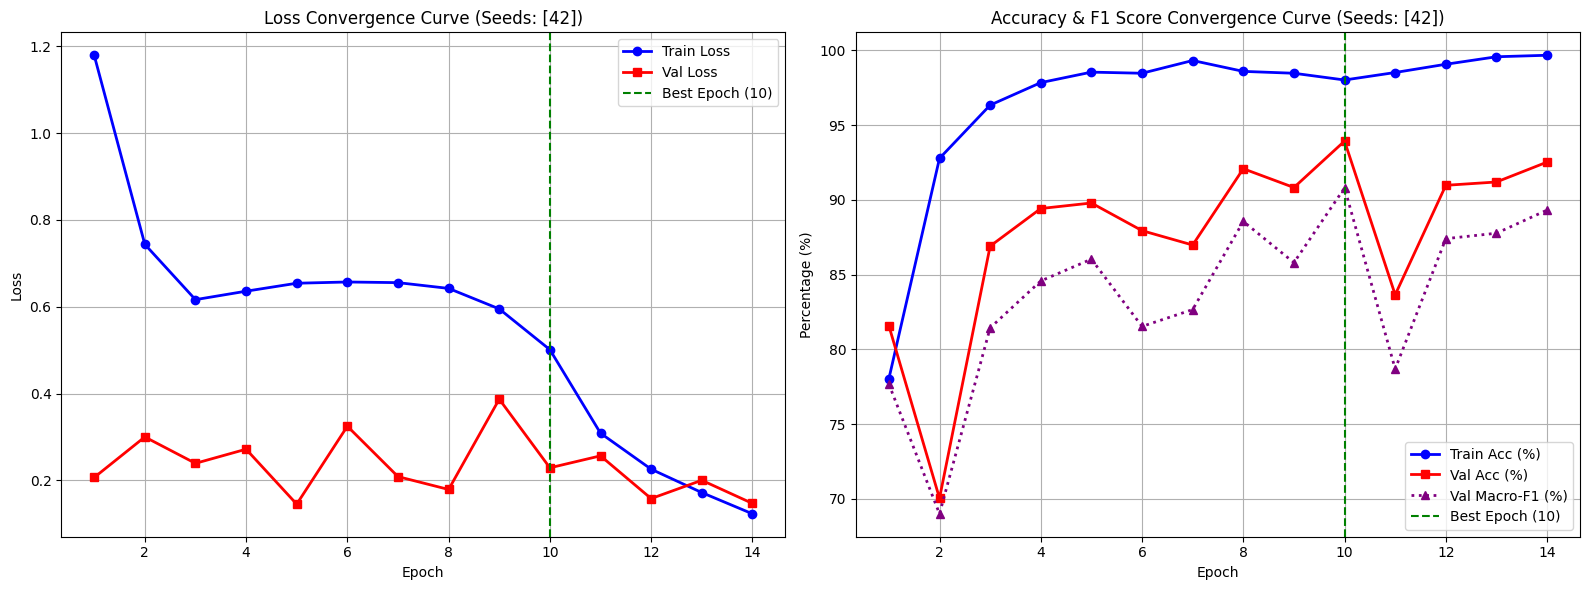

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. CẤU HÌNH CÁC SEED CẦN HIỂN THỊ
# ==========================================
seeds_to_plot = [42]  # Thêm nhiều seed nếu muốn: [42, 100, 2024, 777, 999]

selected_histories = {seed: all_histories[seed] for seed in seeds_to_plot if seed in all_histories}
max_epochs = max(len(h['train_loss']) for h in selected_histories.values())

def get_metric_matrix_selected(metric_name):
    matrix = []
    for seed, h in selected_histories.items():
        vals = h[metric_name]
        padded = vals + [np.nan] * (max_epochs - len(vals))
        matrix.append(padded)
    return np.array(matrix)

# ==========================================
# 2. TÍNH TRUNG BÌNH CÁC SEED ĐƯỢC CHỌN
# ==========================================
train_loss_mean = np.nanmean(get_metric_matrix_selected('train_loss'), axis=0)
val_loss_mean   = np.nanmean(get_metric_matrix_selected('val_loss'), axis=0)
train_acc_mean  = np.nanmean(get_metric_matrix_selected('train_acc'), axis=0) * 100
val_acc_mean    = np.nanmean(get_metric_matrix_selected('val_acc'), axis=0) * 100
val_f1_mean     = np.nanmean(get_metric_matrix_selected('val_f1'), axis=0) * 100

epochs_range = range(1, max_epochs + 1)

# ==========================================
# 3. VẼ ĐỒ THỊ SỰ HỘI TỤ
# ==========================================
plt.figure(figsize=(16, 6))

# ----------------- SUBPLOT 1: LOSS -----------------
plt.subplot(1, 2, 1)

# Nếu chọn 1 seed, vẽ trực tiếp; nếu nhiều seed, vẽ đường mờ nền
if len(selected_histories) > 1:
    for seed, h in selected_histories.items():
        epochs_seed = range(1, len(h['train_loss']) + 1)
        plt.plot(epochs_seed, h['train_loss'], color='blue', alpha=0.15, linestyle='--')
        plt.plot(epochs_seed, h['val_loss'], color='red', alpha=0.15, linestyle='--')

plt.plot(epochs_range, train_loss_mean, label='Train Loss', color='blue', linewidth=2, marker='o')
plt.plot(epochs_range, val_loss_mean, label='Val Loss', color='red', linewidth=2, marker='s')

# Đường nét đứt xanh lá chỉ số Best Epoch
for seed, h in selected_histories.items():
    best_ep = h.get('best_epoch', None)
    if best_ep:
        lbl = f'Best Epoch ({best_ep})' if len(selected_histories) == 1 else f'Best Ep S{seed} ({best_ep})'
        plt.axvline(x=best_ep, color='green', linestyle='--', label=lbl)

plt.title(f'Loss Convergence Curve (Seeds: {seeds_to_plot})')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# ----------------- SUBPLOT 2: ACCURACY & F1 -----------------
plt.subplot(1, 2, 2)

if len(selected_histories) > 1:
    for seed, h in selected_histories.items():
        epochs_seed = range(1, len(h['val_acc']) + 1)
        plt.plot(epochs_seed, [x*100 for x in h['train_acc']], color='blue', alpha=0.15, linestyle='--')
        plt.plot(epochs_seed, [x*100 for x in h['val_acc']], color='red', alpha=0.15, linestyle='--')
        plt.plot(epochs_seed, [x*100 for x in h['val_f1']], color='purple', alpha=0.15, linestyle=':')

plt.plot(epochs_range, train_acc_mean, label='Train Acc (%)', color='blue', linewidth=2, marker='o')
plt.plot(epochs_range, val_acc_mean, label='Val Acc (%)', color='red', linewidth=2, marker='s')
plt.plot(epochs_range, val_f1_mean, label='Val Macro-F1 (%)', color='purple', linewidth=2, linestyle=':', marker='^')

# Đường nét đứt xanh lá chỉ số Best Epoch
for seed, h in selected_histories.items():
    best_ep = h.get('best_epoch', None)
    if best_ep:
        lbl = f'Best Epoch ({best_ep})' if len(selected_histories) == 1 else f'Best Ep S{seed} ({best_ep})'
        plt.axvline(x=best_ep, color='green', linestyle='--', label=lbl)

plt.title(f'Accuracy & F1 Score Convergence Curve (Seeds: {seeds_to_plot})')
plt.xlabel('Epoch')
plt.ylabel('Percentage (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Đánh giá 

In [33]:
import os
import pandas as pd
import torch
from sklearn.metrics import classification_report, accuracy_score, f1_score

# ==========================================================
# 1. CẤU HÌNH LỰA CHỌN SEED CẦN XEM CHI TIẾT
# ==========================================================
# CÁC CHẾ ĐỘ (MODE):
# - 'all'      : Xem chi tiết tất cả các seed
# - 'top_k'    : Chỉ xem K seed có Val F1 cao nhất
# - 'specific' : Chỉ xem danh sách seed tự chọn trong SPECIFIC_SEEDS

MODE = 'specific'          # Chọn: 'all', 'top_k', hoặc 'specific'
TOP_K = 2               # Dùng khi MODE = 'top_k'
SPECIFIC_SEEDS = [42]   # Dùng khi MODE = 'specific'

# Tự động lấy danh sách lớp (target_names)
if 'target_names' not in globals():
    if 'test_dataset' in globals() and hasattr(test_dataset, 'classes'):
        target_names = test_dataset.classes
    else:
        target_names = None

# ==========================================================
# 2. ĐỌC VÀ IN BẢNG XẾP HẠNG TỔNG QUAN TẤT CẢ CÁC SEED
# ==========================================================
summary_csv_path = os.path.join(SAVE_DIR, "seeds_summary.csv")

if os.path.exists(summary_csv_path):
    df_summary = pd.read_csv(summary_csv_path)
else:
    # Nếu chưa có file CSV, tự dựng lại DataFrame từ list summary_results
    df_summary = pd.DataFrame(summary_results)

# Sắp xếp danh sách theo Val F1 giảm dần
df_summary = df_summary.sort_values(by='best_val_f1', ascending=False).reset_index(drop=True)

print("=" * 75)
print("🏆 BẢNG XẾP HẠNG HIỆU NĂNG TẤT CẢ CÁC SEEDS (SẮP XẾP THEO VAL F1)")
print("=" * 75)
print(df_summary[['seed', 'best_epoch', 'best_val_f1', 'model_path']].to_string(index=False))
print("=" * 75)

# ==========================================================
# 3. LỌC DANH SÁCH SEED CẦN IN BÁO CÁO CHI TIẾT
# ==========================================================
if MODE == 'all':
    seeds_to_inspect = df_summary['seed'].tolist()
    print(f"\n📋 [CHẾ ĐỘ: ALL] Đang kiểm tra toàn bộ {len(seeds_to_inspect)} seeds...")

elif MODE == 'top_k':
    seeds_to_inspect = df_summary.head(TOP_K)['seed'].tolist()
    print(f"\n🥇 [CHẾ ĐỘ: TOP_K] Đang kiểm tra Top {TOP_K} seed tốt nhất: {seeds_to_inspect}")

elif MODE == 'specific':
    seeds_to_inspect = [s for s in SPECIFIC_SEEDS if s in df_summary['seed'].values]
    print(f"\n🎯 [CHẾ ĐỘ: SPECIFIC] Đang kiểm tra các seed chỉ định: {seeds_to_inspect}")

# Lấy nhãn thực tế tập test
true_labels = []
for _, labels in test_loader:
    true_labels.extend(labels.numpy())

# ==========================================================
# 4. CHẠY DỰ ĐOÁN VÀ IN BÁO CÁO CHI TIẾT TẬP TEST
# ==========================================================
for seed in seeds_to_inspect:
    model_path = os.path.join(SAVE_DIR, f"best_model_seed_{seed}.pt")
    
    print("\n" + "#" * 65)
    print(f"🔍 BÁO CÁO CHI TIẾT TRÊN TẬP TEST - SEED {seed}")
    print("#" * 65)

    # Load model
    model = MultiExitConvNeXt(num_classes=num_classes, dropout_p=0.3).to(DEVICE)
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    model.eval()

    # Kiểm tra số Exit Heads
    with torch.no_grad():
        sample_img, _ = next(iter(test_loader))
        sample_out = model(sample_img.to(DEVICE))
        num_exits = len(sample_out) if isinstance(sample_out, (list, tuple)) else 1

    all_exit_preds = [[] for _ in range(num_exits)]

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(DEVICE)
            outputs = model(images)
            
            if isinstance(outputs, (list, tuple)):
                for idx, exit_out in enumerate(outputs):
                    _, predicted = exit_out.max(1)
                    all_exit_preds[idx].extend(predicted.cpu().numpy())
            else:
                _, predicted = outputs.max(1)
                all_exit_preds[0].extend(predicted.cpu().numpy())

    # In tóm tắt các Exit của seed này
    print(f"\n[Chỉ số các Exit Head - Seed {seed}]")
    print(f"{'Exit Head':<18} | {'Accuracy (%)':<15} | {'Macro F1-Score':<15}")
    print("-" * 54)
    for idx in range(num_exits):
        exit_label = f"Exit {idx+1} (Final)" if idx == num_exits - 1 else f"Exit {idx+1} (Early)"
        acc = accuracy_score(true_labels, all_exit_preds[idx]) * 100
        f1 = f1_score(true_labels, all_exit_preds[idx], average='macro')
        print(f"{exit_label:<18} | {acc:<15.2f} | {f1:<15.4f}")

    # In Classification Report cho Final Exit
    final_idx = num_exits - 1
    print(f"\n[Classification Report cho Final Exit (Exit {num_exits}) - Seed {seed}]")
    print(classification_report(true_labels, all_exit_preds[final_idx], target_names=target_names, digits=4))

🏆 BẢNG XẾP HẠNG HIỆU NĂNG TẤT CẢ CÁC SEEDS (SẮP XẾP THEO VAL F1)
 seed  best_epoch  best_val_f1                         model_path
   42          10     0.908046 ./saved_runs/best_model_seed_42.pt

🎯 [CHẾ ĐỘ: SPECIFIC] Đang kiểm tra các seed chỉ định: [42]

#################################################################
🔍 BÁO CÁO CHI TIẾT TRÊN TẬP TEST - SEED 42
#################################################################

[Chỉ số các Exit Head - Seed 42]
Exit Head          | Accuracy (%)    | Macro F1-Score 
------------------------------------------------------
Exit 1 (Early)     | 65.77           | 0.4799         
Exit 2 (Early)     | 91.52           | 0.8815         
Exit 3 (Final)     | 91.88           | 0.8884         

[Classification Report cho Final Exit (Exit 3) - Seed 42]
              precision    recall  f1-score   support

       Aorta     0.8603    0.8797    0.8699       133
       Flows     0.9775    0.9909    0.9841       219
       Other     0.9628    0.9028   

In [34]:
import os
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report, accuracy_score, f1_score

# ==========================================================
# 1. CẤU HÌNH DANH SÁCH SEED CẦN ĐÁNH GIÁ (TÙY CHỈNH TẠI ĐÂY)
# ==========================================================
SEEDS_TO_EVAL = [42]
# Điền danh sách seed muốn xem: [42] hoặc [42, 100] hoặc SEEDS

# Tự động xác định target_names (tên các lớp)
if 'target_names' not in globals():
    if 'test_dataset' in globals() and hasattr(test_dataset, 'classes'):
        target_names = test_dataset.classes
    else:
        target_names = None

# Lấy nhãn thực tế của tập test
all_test_labels = []
for _, labels in test_loader:
    all_test_labels.extend(labels.numpy())

print("\n" + "="*70, flush=True)
print(f" 🎯 BÁO CÁO CHI TIẾT TỪNG EXIT HEAD CHO CÁC SEED: {SEEDS_TO_EVAL}", flush=True)
print("="*70, flush=True)

# ==========================================================
# 2. VÒNG LẶP ĐÁNH GIÁ THEO TỪNG SEED ĐƯỢC CHỌN
# ==========================================================
for seed in SEEDS_TO_EVAL:
    model_path = os.path.join(SAVE_DIR, f"best_model_seed_{seed}.pt")
    if not os.path.exists(model_path):
        print(f"\n❌ Không tìm thấy file trọng số cho Seed {seed} tại {model_path}", flush=True)
        continue

    print(f"\n==================================================", flush=True)
    print(f"📌 ĐÁNH GIÁ MÔ HÌNH SEED: {seed}", flush=True)
    print(f"==================================================", flush=True)

    # Nạp lại kiến trúc và trọng số tốt nhất của Seed này
    model = MultiExitConvNeXt(num_classes=num_classes, dropout_p=0.3).to(DEVICE)
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    model.eval()

    # Kiểm tra số lượng Exit Head
    with torch.no_grad():
        sample_img, _ = next(iter(test_loader))
        sample_out = model(sample_img.to(DEVICE))
        
        if isinstance(sample_out, (list, tuple)):
            num_exits = len(sample_out)
        else:
            num_exits = 1

    all_exit_preds = [[] for _ in range(num_exits)]

    # Chạy dự đoán trên toàn bộ tập Test
    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(DEVICE)
            outputs = model(images)
            
            if isinstance(outputs, (list, tuple)):
                for idx, exit_out in enumerate(outputs):
                    _, predicted = exit_out.max(1)
                    all_exit_preds[idx].extend(predicted.cpu().numpy())
            else:
                _, predicted = outputs.max(1)
                all_exit_preds[0].extend(predicted.cpu().numpy())

    # 3. BẢNG TỔNG HỢP CÁC EXIT HEAD CHO SEED NÀY
    print(f"\n[BẢNG CHỈ SỐ CÁC EXIT HEAD - SEED {seed}]", flush=True)
    print(f"{'Exit Head':<18} | {'Accuracy (%)':<15} | {'Macro F1-Score':<15}", flush=True)
    print("-" * 54, flush=True)

    for idx in range(num_exits):
        exit_label = f"Exit {idx+1} (Final)" if idx == num_exits - 1 else f"Exit {idx+1} (Early)"
        acc = accuracy_score(all_test_labels, all_exit_preds[idx]) * 100
        f1 = f1_score(all_test_labels, all_exit_preds[idx], average='macro')
        print(f"{exit_label:<18} | {acc:<15.2f} | {f1:<15.4f}", flush=True)

    # 4. IN BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1 PER CLASS) CHO TỪNG EXIT
    print("\n--------------------------------------------------", flush=True)
    print(f"📊 BÁO CÁO CHI TIẾT TỪNG EXIT HEAD (SEED {seed})", flush=True)
    print("--------------------------------------------------", flush=True)
    
    for idx in range(num_exits):
        exit_title = f"FINAL EXIT (EXIT {idx+1})" if idx == num_exits - 1 else f"EARLY EXIT {idx+1}"
        print(f"\n🔍 [BÁO CÁO CHI TIẾT - {exit_title}]", flush=True)
        print(classification_report(all_test_labels, all_exit_preds[idx], target_names=target_names, digits=4), flush=True)


 🎯 BÁO CÁO CHI TIẾT TỪNG EXIT HEAD CHO CÁC SEED: [42]

📌 ĐÁNH GIÁ MÔ HÌNH SEED: 42

[BẢNG CHỈ SỐ CÁC EXIT HEAD - SEED 42]
Exit Head          | Accuracy (%)    | Macro F1-Score 
------------------------------------------------------
Exit 1 (Early)     | 65.77           | 0.4799         
Exit 2 (Early)     | 91.52           | 0.8815         
Exit 3 (Final)     | 91.88           | 0.8884         

--------------------------------------------------
📊 BÁO CÁO CHI TIẾT TỪNG EXIT HEAD (SEED 42)
--------------------------------------------------

🔍 [BÁO CÁO CHI TIẾT - EARLY EXIT 1]
              precision    recall  f1-score   support

       Aorta     0.2273    0.1128    0.1508       133
       Flows     0.9394    0.4247    0.5849       219
       Other     0.9326    0.7837    0.8517       689
      V sign     0.4233    0.9382    0.5834       259
      X sign     0.2623    0.2025    0.2286        79

    accuracy                         0.6577      1379
   macro avg     0.5570    0.4924    0